<h1 style="background-color:#081E9F; color:white; padding:3px 6px; border-radius:4px; font-weight:bold;">
Home Credit Default Risk 
</h1>

<h2 style="background-color:#007DFF; color:white; padding:3px 6px; border-radius:4px; font-weight:bold;">
About Dataset
</h2>

<h2 style="background-color:#007DFF; color:white; padding:3px 6px; border-radius:4px; font-weight:bold;">
Library Imports 
</h2>

In [1]:
import sqlite3
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import shap
import numpy as np
import warnings

%load_ext kedro.ipython

c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[09/10/26 08:15:56] INFO     Using                                                                  ]8;id=16299169;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\framework\project\__init__.py\__init__.py]8;;\:]8;id=16299170;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\framework\project\__init__.py#302\302]8;;\
                             'c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-pac                
                             kages\kedro\framework\project\rich_logging.yml' as logging                            
                             configuration.                                                                        

                    INFO     Registered line magic '%reload_kedro'                                   ]8;id=16299177;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\ipython\__init__.py\__init__.py]8;;\:]8;id=16299178;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\ipython\__init__.py#67\67]8;;\

                    INFO     Registered line magic '%load_node'                                      ]8;id=16299184;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\ipython\__init__.py\__init__.py]8;;\:]8;id=16299185;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\ipython\__init__.py#69\69]8;;\

                    INFO     Resolved project path as: c:\Users\mariana\home-credit-default-risk.   ]8;id=16299191;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\ipython\__init__.py\__init__.py]8;;\:]8;id=16299192;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\ipython\__init__.py#193\193]8;;\
                             To set a different path, run '%reload_kedro <project_root>'                           

[09/10/26 08:16:01] INFO     No typed parameter requirements found, returning original   ]8;id=16299199;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\validation\parameter_validator.py\parameter_validator.py]8;;\:]8;id=16299200;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\validation\parameter_validator.py#124\124]8;;\
                             parameters                                                                            

[09/10/26 08:16:03] INFO     Kedro is sending anonymous usage data with the sole purpose of improving ]8;id=16299207;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro_telemetry\plugin.py\plugin.py]8;;\:]8;id=16299208;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro_telemetry\plugin.py#273\273]8;;\
                             the product. No personal data or IP addresses are stored on our side. To              
                             opt out, set the `KEDRO_DISABLE_TELEMETRY` or `DO_NOT_TRACK` environment              
                             variables, or create a `.telemetry` file in the current working                       
                             directory with the contents `consent: false`. To hide this message,                   
                             explicitly grant or deny consent. Read more at                                        
                             https://docs.kedro.org/en/stable/about/telemetry/                                     

[09/10/26 08:16:04] INFO     Kedro project home_credit_default_risk                                 ]8;id=16299214;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\ipython\__init__.py\__init__.py]8;;\:]8;id=16299215;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\ipython\__init__.py#159\159]8;;\

                    INFO     Defined global variable 'context', 'session', 'catalog' and            ]8;id=16299221;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\ipython\__init__.py\__init__.py]8;;\:]8;id=16299222;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\ipython\__init__.py#160\160]8;;\
                             'pipelines'                                                                           

<h2 style="background-color:#007DFF; color:white; padding:3px 6px; border-radius:4px; font-weight:bold;">
Dataset Import
</h2>

In [32]:
print(os.path.abspath("column_descriptions.txt"))
with open("column_descriptions.txt", "w", encoding="utf-8") as f:
    for table in columns_description["Table"].unique():
        f.write(f"\n=== {table} ===\n")
        table_desc = columns_description[columns_description["Table"] == table]
        for _, row in table_desc.iterrows():
            f.write(f"{row['Row']}: {row['Description']}\n")

print("Saved to column_descriptions.txt")

c:\Users\mariana\home-credit-default-risk\notebooks\column_descriptions.txt
Saved to column_descriptions.txt


In [2]:
application_train = catalog.load("application_train_processed")
application_test = catalog.load("application_test_processed")
bureau = catalog.load("bureau_processed")
bureau_balance = catalog.load("bureau_balance_processed")
previous_application = catalog.load("previous_application_processed")
POS_CASH_balance = catalog.load("POS_CASH_balance_processed")
installments_payments = catalog.load("installments_payments_processed")
credit_card_balance = catalog.load("credit_card_balance_processed")

                    INFO     Loading data from application_train_processed (ParquetDataset)... ]8;id=16299229;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=16299230;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py#1050\1050]8;;\

[09/10/26 08:16:05] INFO     Loading data from application_test_processed (ParquetDataset)...  ]8;id=16299235;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=16299236;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py#1050\1050]8;;\

                    INFO     Loading data from bureau_processed (ParquetDataset)...            ]8;id=16299241;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=16299242;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py#1050\1050]8;;\

[09/10/26 08:16:06] INFO     Loading data from bureau_balance_processed (ParquetDataset)...    ]8;id=16299247;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=16299248;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py#1050\1050]8;;\

                    INFO     Loading data from previous_application_processed                  ]8;id=16299253;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=16299254;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py#1050\1050]8;;\
                             (ParquetDataset)...                                                                   

[09/10/26 08:16:07] INFO     Loading data from POS_CASH_balance_processed (ParquetDataset)...  ]8;id=16299259;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=16299260;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py#1050\1050]8;;\

[09/10/26 08:16:08] INFO     Loading data from installments_payments_processed                 ]8;id=16299265;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=16299266;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py#1050\1050]8;;\
                             (ParquetDataset)...                                                                   

[09/10/26 08:16:09] INFO     Loading data from credit_card_balance_processed                   ]8;id=16299271;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=16299272;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py#1050\1050]8;;\
                             (ParquetDataset)...                                                                   

<h2 style="background-color:#007DFF; color:white; padding:3px 6px; border-radius:4px; font-weight:bold;">
Data Exploration
</h2>

In [3]:
dfs = {
    "application_train": application_train,
    "application_test": application_test,
    "bureau": bureau,
    "bureau_balance": bureau_balance,
    "previous_application": previous_application,
    "POS_CASH_balance": POS_CASH_balance,
    "installments_payments": installments_payments,
    "credit_card_balance": credit_card_balance,
}

In [4]:
for name, df in {
    "application_train": application_train,
    "application_test": application_test,
    "bureau": bureau,
    "bureau_balance": bureau_balance,
    "previous_application": previous_application,
    "POS_CASH_balance": POS_CASH_balance,
    "installments_payments": installments_payments,
    "credit_card_balance": credit_card_balance
}.items():
    
    print(f"\n{name}: {df.shape}")
    display(df.head())
    display(df.tail())
    display(df.describe().T)
    display(df.info())



application_train: (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
307506,456251,0,Cash loans,M,N,N,0,157500.0,254700.0,27558.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307507,456252,0,Cash loans,F,N,Y,0,72000.0,269550.0,12001.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307508,456253,0,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,...,0,0,0,0,1.0,0.0,0.0,1.0,0.0,1.0
307509,456254,1,Cash loans,F,N,Y,0,171000.0,370107.0,20205.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
307510,456255,0,Cash loans,F,N,N,0,157500.0,675000.0,49117.5,...,0,0,0,0,0.0,0.0,0.0,2.0,0.0,1.0


,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.518577,102790.175348,100002.0,189145.5,278202.0,367142.5,456255.0
TARGET,307511.0,0.080729,0.272419,0.0,0.0,0.0,0.0,1.0
CNT_CHILDREN,307511.0,0.417052,0.722121,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599026.000000,402490.781250,45000.0,270000.0,513531.0,808650.0,4050000.0
...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,265992.0,0.007000,0.110757,0.0,0.0,0.0,0.0,9.0
AMT_REQ_CREDIT_BUREAU_WEEK,265992.0,0.034362,0.204685,0.0,0.0,0.0,0.0,8.0
AMT_REQ_CREDIT_BUREAU_MON,265992.0,0.267395,0.916002,0.0,0.0,0.0,0.0,27.0
AMT_REQ_CREDIT_BUREAU_QRT,265992.0,0.265474,0.794056,0.0,0.0,0.0,0.0,261.0


<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: category(16), float32(64), float64(1), int16(2), int32(2), int8(37)
memory usage: 96.5 MB

application_test: (48744, 121)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100001,Cash loans,F,N,Y,0,135000.0,568800.0,20560.5,450000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
1,100005,Cash loans,M,N,Y,0,99000.0,222768.0,17370.0,180000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
2,100013,Cash loans,M,Y,Y,0,202500.0,663264.0,69777.0,630000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,4.0
3,100028,Cash loans,F,N,Y,2,315000.0,1575000.0,49018.5,1575000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
4,100038,Cash loans,M,Y,N,1,180000.0,625500.0,32067.0,625500.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


... (23 outputs left out)

,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,AMT_BALANCE,AMT_CREDIT_LIMIT_ACTUAL,AMT_DRAWINGS_ATM_CURRENT,AMT_DRAWINGS_CURRENT,AMT_DRAWINGS_OTHER_CURRENT,AMT_DRAWINGS_POS_CURRENT,AMT_INST_MIN_REGULARITY,...,AMT_RECIVABLE,AMT_TOTAL_RECEIVABLE,CNT_DRAWINGS_ATM_CURRENT,CNT_DRAWINGS_CURRENT,CNT_DRAWINGS_OTHER_CURRENT,CNT_DRAWINGS_POS_CURRENT,CNT_INSTALMENT_MATURE_CUM,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,2562384,378907,-6,56.970,135000,0.0,877.5,0.0,877.5,1700.325,...,0.000,0.000,0.0,1,0.0,1.0,35.0,Active,0,0
1,2582071,363914,-1,63975.555,45000,2250.0,2250.0,0.0,0.0,2250.000,...,64875.555,64875.555,1.0,1,0.0,0.0,69.0,Active,0,0
2,1740877,371185,-7,31815.225,450000,0.0,0.0,0.0,0.0,2250.000,...,31460.085,31460.085,0.0,0,0.0,0.0,30.0,Active,0,0
3,1389973,337855,-4,236572.110,225000,2250.0,2250.0,0.0,0.0,11795.760,...,233048.970,233048.970,1.0,1,0.0,0.0,10.0,Active,0,0
4,1891521,126868,-1,453919.455,450000,0.0,11547.0,0.0,11547.0,22924.890,...,453919.455,453919.455,0.0,1,0.0,1.0,101.0,Active,0,0


,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,AMT_BALANCE,AMT_CREDIT_LIMIT_ACTUAL,AMT_DRAWINGS_ATM_CURRENT,AMT_DRAWINGS_CURRENT,AMT_DRAWINGS_OTHER_CURRENT,AMT_DRAWINGS_POS_CURRENT,AMT_INST_MIN_REGULARITY,...,AMT_RECIVABLE,AMT_TOTAL_RECEIVABLE,CNT_DRAWINGS_ATM_CURRENT,CNT_DRAWINGS_CURRENT,CNT_DRAWINGS_OTHER_CURRENT,CNT_DRAWINGS_POS_CURRENT,CNT_INSTALMENT_MATURE_CUM,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
3840307,1036507,328243,-9,0.000,45000,NaN,0.0,NaN,NaN,0.0,...,0.000,0.000,NaN,0,NaN,NaN,0.0,Active,0,0
3840308,1714892,347207,-9,0.000,45000,0.0,0.0,0.0,0.0,0.0,...,0.000,0.000,0.0,0,0.0,0.0,23.0,Active,0,0
3840309,1302323,215757,-9,275784.975,585000,270000.0,270000.0,0.0,0.0,2250.0,...,273093.975,273093.975,2.0,2,0.0,0.0,18.0,Active,0,0
3840310,1624872,430337,-10,0.000,450000,NaN,0.0,NaN,NaN,0.0,...,0.000,0.000,NaN,0,NaN,NaN,0.0,Active,0,0
3840311,2411345,236760,-10,0.000,157500,0.0,0.0,0.0,0.0,0.0,...,0.000,0.000,0.0,0,0.0,0.0,21.0,Completed,0,0


,count,mean,std,min,25%,50%,75%,max
SK_ID_PREV,3840312.0,1.904504e+06,536469.470563,1000018.000,1434385.00,1897122.0,2.369328e+06,2843496.000
SK_ID_CURR,3840312.0,2.783242e+05,102704.475133,100006.000,189517.00,278396.0,3.675800e+05,456250.000
MONTHS_BALANCE,3840312.0,-3.452192e+01,26.667751,-96.000,-55.00,-28.0,-1.100000e+01,-1.000
AMT_BALANCE,3840312.0,5.830016e+04,106307.031024,-420250.185,0.00,0.0,8.904669e+04,1505902.185
AMT_CREDIT_LIMIT_ACTUAL,3840312.0,1.538080e+05,165145.699525,0.000,45000.00,112500.0,1.800000e+05,1350000.000
AMT_DRAWINGS_ATM_CURRENT,3090496.0,5.961325e+03,28225.688578,-6827.310,0.00,0.0,0.000000e+00,2115000.000
AMT_DRAWINGS_CURRENT,3840312.0,7.433388e+03,33846.077333,-6211.620,0.00,0.0,0.000000e+00,2287098.315
AMT_DRAWINGS_OTHER_CURRENT,3090496.0,2.881696e+02,8201.989345,0.000,0.00,0.0,0.000000e+00,1529847.000
AMT_DRAWINGS_POS_CURRENT,3090496.0,2.968805e+03,20796.887047,0.000,0.00,0.0,0.000000e+00,2239274.160
AMT_INST_MIN_REGULARITY,3535076.0,3.540204e+03,5600.154122,0.000,0.00,0.0,6.633911e+03,202882.005


<class 'pandas.DataFrame'>
RangeIndex: 3840312 entries, 0 to 3840311
Data columns (total 23 columns):
 #   Column                      Dtype   
---  ------                      -----   
 0   SK_ID_PREV                  int32   
 1   SK_ID_CURR                  int32   
 2   MONTHS_BALANCE              int8    
 3   AMT_BALANCE                 float64 
 4   AMT_CREDIT_LIMIT_ACTUAL     int32   
 5   AMT_DRAWINGS_ATM_CURRENT    float64 
 6   AMT_DRAWINGS_CURRENT        float64 
 7   AMT_DRAWINGS_OTHER_CURRENT  float64 
 8   AMT_DRAWINGS_POS_CURRENT    float64 
 9   AMT_INST_MIN_REGULARITY     float64 
 10  AMT_PAYMENT_CURRENT         float64 
 11  AMT_PAYMENT_TOTAL_CURRENT   float64 
 12  AMT_RECEIVABLE_PRINCIPAL    float64 
 13  AMT_RECIVABLE               float64 
 14  AMT_TOTAL_RECEIVABLE        float64 
 15  CNT_DRAWINGS_ATM_CURRENT    float32 
 16  CNT_DRAWINGS_CURRENT        int16   
 17  CNT_DRAWINGS_OTHER_CURRENT  float32 
 18  CNT_DRAWINGS_POS_CURRENT    float32 
 19  CNT_INSTALM

-------------------------------------------------------------------
Checking for missing values
-------------------------------------------------------------------

In [5]:
cols_where_zero_means_missing = []  # fill this in after checking

for name, df in dfs.items():
    for col in cols_where_zero_means_missing:
        if col in df.columns:
            df[col] = df[col].replace(0, np.nan)

cols_where_zero_means_missing

for name, df in dfs.items():
    missing = df.isnull().sum().sort_values(ascending=False)
    missing = missing[missing > 0]
    missing_pct = (missing / len(df) * 100).round(2)
    summary = pd.DataFrame({"n_missing": missing, "pct_missing": missing_pct})
    print(f"\n{name}: {len(df)} entries, {missing.shape[0]} columns with nulls")
    display(summary.head(20))


application_train: 307511 entries, 67 columns with nulls


,n_missing,pct_missing
COMMONAREA_AVG,214865,69.87
COMMONAREA_MODE,214865,69.87
COMMONAREA_MEDI,214865,69.87
NONLIVINGAPARTMENTS_MEDI,213514,69.43
NONLIVINGAPARTMENTS_MODE,213514,69.43
NONLIVINGAPARTMENTS_AVG,213514,69.43
FONDKAPREMONT_MODE,210295,68.39
LIVINGAPARTMENTS_AVG,210199,68.35
LIVINGAPARTMENTS_MEDI,210199,68.35
LIVINGAPARTMENTS_MODE,210199,68.35



application_test: 48744 entries, 64 columns with nulls


,n_missing,pct_missing
COMMONAREA_AVG,33495,68.72
COMMONAREA_MEDI,33495,68.72
COMMONAREA_MODE,33495,68.72
NONLIVINGAPARTMENTS_AVG,33347,68.41
NONLIVINGAPARTMENTS_MEDI,33347,68.41
NONLIVINGAPARTMENTS_MODE,33347,68.41
FONDKAPREMONT_MODE,32797,67.28
LIVINGAPARTMENTS_MEDI,32780,67.25
LIVINGAPARTMENTS_AVG,32780,67.25
LIVINGAPARTMENTS_MODE,32780,67.25



bureau: 1716428 entries, 7 columns with nulls


,n_missing,pct_missing
AMT_ANNUITY,1226791,71.47
AMT_CREDIT_MAX_OVERDUE,1124488,65.51
DAYS_ENDDATE_FACT,633653,36.92
AMT_CREDIT_SUM_LIMIT,591780,34.48
AMT_CREDIT_SUM_DEBT,257669,15.01
DAYS_CREDIT_ENDDATE,105553,6.15
AMT_CREDIT_SUM,13,0.00


... (6 outputs left out)


installments_payments: 13605401 entries, 2 columns with nulls


,n_missing,pct_missing
AMT_PAYMENT,2905,0.02
DAYS_ENTRY_PAYMENT,2905,0.02



credit_card_balance: 3840312 entries, 9 columns with nulls


,n_missing,pct_missing
AMT_PAYMENT_CURRENT,767988,20.00
CNT_DRAWINGS_POS_CURRENT,749816,19.52
AMT_DRAWINGS_ATM_CURRENT,749816,19.52
CNT_DRAWINGS_ATM_CURRENT,749816,19.52
AMT_DRAWINGS_POS_CURRENT,749816,19.52
AMT_DRAWINGS_OTHER_CURRENT,749816,19.52
CNT_DRAWINGS_OTHER_CURRENT,749816,19.52
CNT_INSTALMENT_MATURE_CUM,305236,7.95
AMT_INST_MIN_REGULARITY,305236,7.95


Some columns are heavly dominated by missing values, therefore some columns are porbably going to be erased.

-------------------------------------------------------------------
Checking for unwanted negative values 
-------------------------------------------------------------------

In [6]:
for name, df in dfs.items():
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    neg_summary = {}
    for col in numeric_cols:
        n_neg = (df[col] < 0).sum()
        if n_neg > 0:
            neg_summary[col] = n_neg
    if neg_summary:
        print(f"\n{name}: {len(neg_summary)} columns with negative values")
        display(pd.Series(neg_summary).sort_values(ascending=False))


application_train: 5 columns with negative values



DAYS_BIRTH                307511
DAYS_ID_PUBLISH           307495
DAYS_REGISTRATION         307431
DAYS_LAST_PHONE_CHANGE    269838
DAYS_EMPLOYED             252135
dtype: int64


application_test: 6 columns with negative values



DAYS_BIRTH                     48744
DAYS_ID_PUBLISH                48739
DAYS_REGISTRATION              48731
DAYS_LAST_PHONE_CHANGE         42943
DAYS_EMPLOYED                  39470
REGION_RATING_CLIENT_W_CITY        1
dtype: int64


bureau: 6 columns with negative values



DAYS_CREDIT             1716403
DAYS_CREDIT_UPDATE      1715806
DAYS_ENDDATE_FACT       1082711
DAYS_CREDIT_ENDDATE     1007389
AMT_CREDIT_SUM_DEBT        8418
AMT_CREDIT_SUM_LIMIT        351
dtype: int64

... (6 outputs left out)


installments_payments: 2 columns with negative values



DAYS_INSTALMENT       13605401
DAYS_ENTRY_PAYMENT    13602496
dtype: int64


credit_card_balance: 7 columns with negative values



MONTHS_BALANCE              3840312
AMT_RECIVABLE                109338
AMT_TOTAL_RECEIVABLE         109330
AMT_RECEIVABLE_PRINCIPAL       2428
AMT_BALANCE                    2345
AMT_DRAWINGS_CURRENT              3
AMT_DRAWINGS_ATM_CURRENT          1
dtype: int64

As we can see, most columns with negative values contain information about days and months. Since it is do predominant, we will assume these values as the past with 'today' being day 0.
So if the column 'DAYS_BIRTH' is -10 000, the candidate is 10 000 days old.

-------------------------------------------------------------------
Verifying unique values
-------------------------------------------------------------------

In [7]:
for name, df in dfs.items():
    print(f"\n{name}:")
    nunique = df.nunique().sort_values()
    display(nunique)
    
    # flag likely-categorical (low cardinality, object dtype)
    cat_candidates = df.select_dtypes(include='object').columns
    for col in cat_candidates:
        print(f"  {col}: {df[col].unique()[:10]}")


application_train:



TARGET                     2
NAME_CONTRACT_TYPE         2
FLAG_OWN_REALTY            2
FLAG_OWN_CAR               2
FLAG_WORK_PHONE            2
                       ...  
DAYS_REGISTRATION      15688
DAYS_BIRTH             17460
EXT_SOURCE_1          114584
EXT_SOURCE_2          119831
SK_ID_CURR            307511
Length: 122, dtype: int64


application_test:



FLAG_DOCUMENT_20         1
FLAG_DOCUMENT_21         1
FLAG_DOCUMENT_16         1
FLAG_DOCUMENT_17         1
FLAG_DOCUMENT_15         1
                     ...  
DAYS_REGISTRATION    12618
DAYS_BIRTH           15477
EXT_SOURCE_1         27207
EXT_SOURCE_2         38885
SK_ID_CURR           48744
Length: 121, dtype: int64


bureau:



CREDIT_CURRENCY                 4
CREDIT_ACTIVE                   4
CNT_CREDIT_PROLONG             10
CREDIT_TYPE                    15
CREDIT_DAY_OVERDUE            942
AMT_CREDIT_SUM_OVERDUE       1616
DAYS_ENDDATE_FACT            2917
DAYS_CREDIT                  2923
DAYS_CREDIT_UPDATE           2982
DAYS_CREDIT_ENDDATE         14096
AMT_ANNUITY                 40321
AMT_CREDIT_SUM_LIMIT        51726
AMT_CREDIT_MAX_OVERDUE      68251
AMT_CREDIT_SUM_DEBT        226537
AMT_CREDIT_SUM             236708
SK_ID_CURR                 305811
SK_ID_BUREAU              1716428
dtype: int64

... (6 outputs left out)


installments_payments:



NUM_INSTALMENT_VERSION        65
NUM_INSTALMENT_NUMBER        277
DAYS_INSTALMENT             2922
DAYS_ENTRY_PAYMENT          3039
SK_ID_CURR                339587
AMT_INSTALMENT            902539
AMT_PAYMENT               944235
SK_ID_PREV                997752
dtype: int64


credit_card_balance:



NAME_CONTRACT_STATUS                7
CNT_DRAWINGS_OTHER_CURRENT         11
CNT_DRAWINGS_ATM_CURRENT           44
MONTHS_BALANCE                     96
CNT_INSTALMENT_MATURE_CUM         121
CNT_DRAWINGS_CURRENT              129
CNT_DRAWINGS_POS_CURRENT          133
AMT_CREDIT_LIMIT_ACTUAL           181
SK_DPD_DEF                        378
SK_DPD                            917
AMT_DRAWINGS_OTHER_CURRENT       1832
AMT_DRAWINGS_ATM_CURRENT         2267
SK_ID_CURR                     103558
SK_ID_PREV                     104307
AMT_PAYMENT_CURRENT            163209
AMT_DRAWINGS_POS_CURRENT       168748
AMT_PAYMENT_TOTAL_CURRENT      182957
AMT_DRAWINGS_CURRENT           187005
AMT_INST_MIN_REGULARITY        312266
AMT_RECEIVABLE_PRINCIPAL      1195839
AMT_RECIVABLE                 1338878
AMT_TOTAL_RECEIVABLE          1339008
AMT_BALANCE                   1347904
dtype: int64

In [8]:
for name, df in dfs.items():
    n_entries = len(df)
    if "SK_ID_CURR" in df.columns:
        n_unique_ids = df["SK_ID_CURR"].nunique()
        print(f"{name}: {n_entries} entries, {n_unique_ids} unique SK_ID_CURR")
    else:
        n_unique_bureau = df["SK_ID_BUREAU"].nunique()
        print(f"{name}: {n_entries} entries, {n_unique_bureau} unique SK_ID_BUREAU (no SK_ID_CURR — links via bureau)")


application_train: 307511 entries, 307511 unique SK_ID_CURR
application_test: 48744 entries, 48744 unique SK_ID_CURR
bureau: 1716428 entries, 305811 unique SK_ID_CURR
bureau_balance: 27299925 entries, 817395 unique SK_ID_BUREAU (no SK_ID_CURR — links via bureau)
previous_application: 1670214 entries, 338857 unique SK_ID_CURR
POS_CASH_balance: 10001358 entries, 337252 unique SK_ID_CURR
installments_payments: 13605401 entries, 339587 unique SK_ID_CURR
credit_card_balance: 3840312 entries, 103558 unique SK_ID_CURR


'SK_ID_CURR' is what identifies the applicant, which is present in all datasets. Therefore, when the entries of the dataset don't match the unique values of the column 'SK_ID_CURR', it means we have many credit records of the same applicant.


Any column with 'nunique == 1' show constant values.


<h2 style="background-color:#007DFF; color:white; padding:3px 6px; border-radius:4px; font-weight:bold;">
Histograms and Boxplots
</h2>

-------------------------------------------------------------------
Histograms
-------------------------------------------------------------------

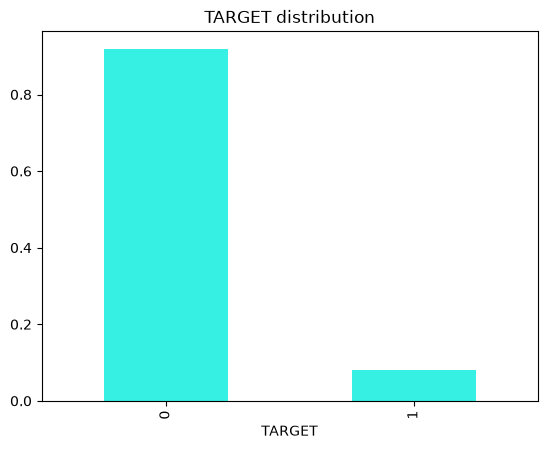

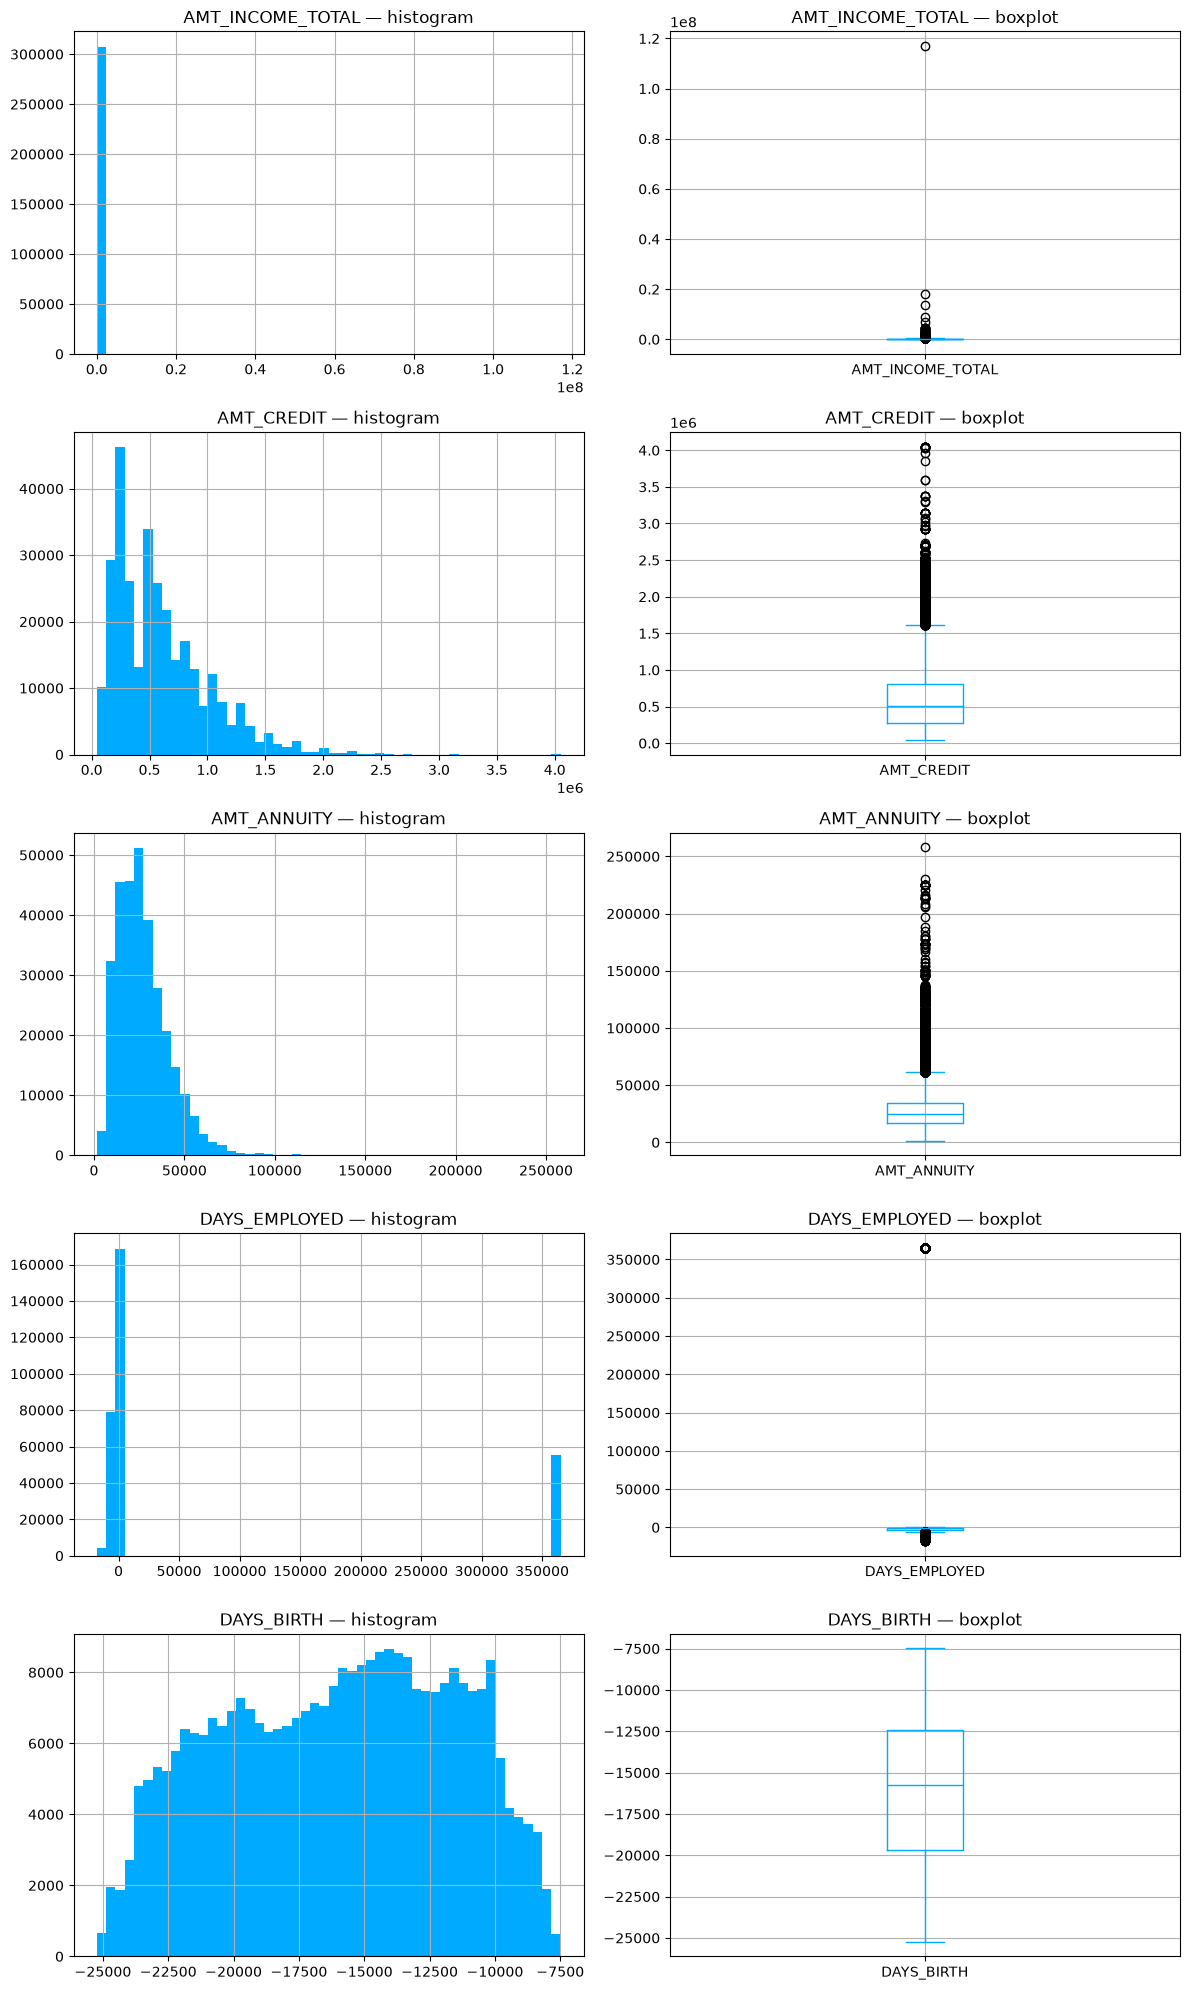

In [9]:
application_train["TARGET"].value_counts(normalize=True).plot(kind="bar", title="TARGET distribution", color="#37f0e4")
plt.show()

num_cols = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "DAYS_EMPLOYED", "DAYS_BIRTH"]

fig, axes = plt.subplots(len(num_cols), 2, figsize=(12, 4 * len(num_cols)))
for i, col in enumerate(num_cols):
    application_train[col].hist(bins=50, ax=axes[i, 0], color = "#00aaff")
    axes[i, 0].set_title(f"{col} — histogram")
    application_train.boxplot(column=col, ax=axes[i, 1], color = "#00aaff")
    axes[i, 1].set_title(f"{col} — boxplot")
plt.tight_layout()
plt.show()


-------------------------------------------------------------------
Correlation between features
-------------------------------------------------------------------

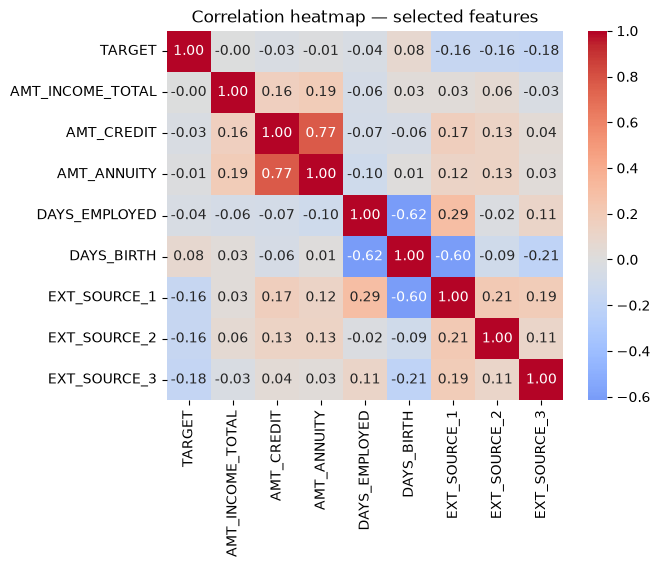

In [10]:
cols_of_interest = ["TARGET", "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY",
                     "DAYS_EMPLOYED", "DAYS_BIRTH", "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]

corr_matrix = application_train[cols_of_interest].corr()
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation heatmap — selected features")
plt.show()


quick checks 

In [11]:
"TARGET" in application_test.columns


False

In [12]:
application_train["DAYS_EMPLOYED"].value_counts()


DAYS_EMPLOYED
 365243    55374
-200         156
-224         152
-199         151
-230         151
           ...  
-12316         1
-11100         1
-12971         1
-11084         1
-8694          1
Name: count, Length: 12574, dtype: int64

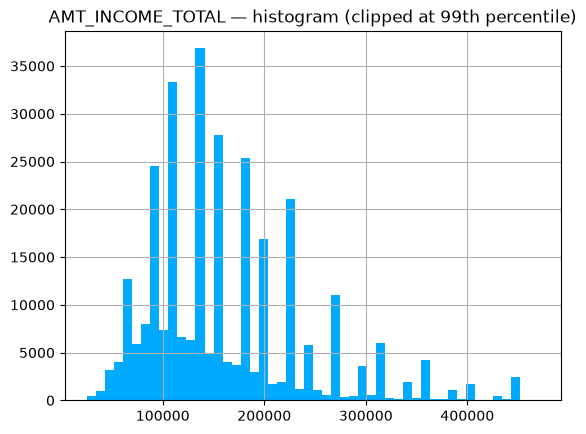

In [13]:
income_clipped = application_train["AMT_INCOME_TOTAL"][application_train["AMT_INCOME_TOTAL"] < application_train["AMT_INCOME_TOTAL"].quantile(0.99)]
income_clipped.hist(bins=50, color = "#00aaff")
plt.title("AMT_INCOME_TOTAL — histogram (clipped at 99th percentile)")
plt.show()

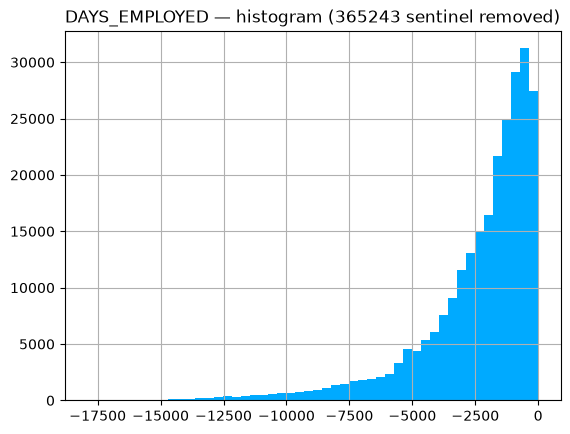

In [14]:
days_employed_clean = application_train["DAYS_EMPLOYED"].replace(365243, np.nan)

days_employed_clean.hist(bins=50, color = "#00aaff")
plt.title("DAYS_EMPLOYED — histogram (365243 sentinel removed)")
plt.show()

In [15]:
ext_source_cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
application_train[ext_source_cols].isnull().mean().mul(100).round(2)



EXT_SOURCE_1    56.38
EXT_SOURCE_2     0.21
EXT_SOURCE_3    19.83
dtype: float64

<h2 style="background-color:#007DFF; color:white; padding:3px 6px; border-radius:4px; font-weight:bold;">
Feature Engineering
</h2>

In [26]:
columns_description = pd.read_csv(
    "C:/Users/mariana/Documents/Portefolio/HomeCredit/HomeCredit_columns_description.csv",
    encoding="latin-1"  # this file sometimes has encoding issues with the default utf-8
)
columns_description[columns_description["Table"] == "POS_CASH_balance.csv"]


,Unnamed: 0,Table,Row,Description,Special
142,145,POS_CASH_balance.csv,SK_ID_PREV,ID of previous credit in Home Credit related t...,NaN
143,146,POS_CASH_balance.csv,SK_ID_CURR,ID of loan in our sample,NaN
144,147,POS_CASH_balance.csv,MONTHS_BALANCE,Month of balance relative to application date ...,time only relative to the application
145,148,POS_CASH_balance.csv,CNT_INSTALMENT,Term of previous credit (can change over time),NaN
146,149,POS_CASH_balance.csv,CNT_INSTALMENT_FUTURE,Installments left to pay on the previous credit,NaN
147,150,POS_CASH_balance.csv,NAME_CONTRACT_STATUS,Contract status during the month,NaN
148,151,POS_CASH_balance.csv,SK_DPD,DPD (days past due) during the month of previo...,NaN
149,152,POS_CASH_balance.csv,SK_DPD_DEF,DPD during the month with tolerance (debts wit...,NaN


In [27]:
pos_cash_desc = columns_description[columns_description["Table"] == "POS_CASH_balance.csv"]
for _, row in pos_cash_desc.iterrows():
    print(f"{row['Row']}: {row['Description']}")


SK_ID_PREV : ID of previous credit in Home Credit related to loan in our sample. (One loan in our sample can have 0,1,2 or more previous loans in Home Credit)
SK_ID_CURR: ID of loan in our sample
MONTHS_BALANCE: Month of balance relative to application date (-1 means the information to the freshest monthly snapshot, 0 means the information at application - often it will be the same as -1 as many banks are not updating the information to Credit Bureau regularly )
CNT_INSTALMENT: Term of previous credit (can change over time)
CNT_INSTALMENT_FUTURE: Installments left to pay on the previous credit
NAME_CONTRACT_STATUS: Contract status during the month
SK_DPD: DPD (days past due) during the month of previous credit
SK_DPD_DEF: DPD during the month with tolerance (debts with low loan amounts are ignored) of the previous credit


<h2 style="background-color:#007DFF; color:white; padding:3px 6px; border-radius:4px; font-weight:bold;">
Missing Values Treatment
</h2>

In [16]:
X_train_imputed = catalog.load("X_train_imputed")
X_test_imputed = catalog.load("X_test_imputed")

print(f"X_train_imputed: {X_train_imputed.shape}")
print(f"X_test_imputed: {X_test_imputed.shape}")    

print(f"\nRemaining missing values:")
print(f"X_train_imputed: {X_train_imputed.isnull().sum().sum()}")
print(f"X_test_imputed: {X_test_imputed.isnull().sum().sum()}") 

[09/10/26 08:16:43] INFO     Loading data from X_train_imputed (ParquetDataset)...             ]8;id=16299277;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=16299278;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py#1050\1050]8;;\

                    INFO     Loading data from X_test_imputed (ParquetDataset)...              ]8;id=16299283;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=16299284;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py#1050\1050]8;;\

X_train_imputed: (246008, 80)
X_test_imputed: (61503, 80)

Remaining missing values:
X_train_imputed: 0
X_test_imputed: 0


<h2 style="background-color:#007DFF; color:white; padding:3px 6px; border-radius:4px; font-weight:bold;">
Outlier Analysis
</h2>

The **IQR (Interquartile Range)** is defined as:

$$IQR = Q3 - Q1$$

Where the outlier bounds are:

$$\text{Lower bound} = Q1 - 1.5 \times IQR$$
$$\text{Upper bound} = Q3 + 1.5 \times IQR$$

In [17]:
def iqr_capping(df, cols):
    results = {}
    for col in cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        outliers = ((df[col] < lower) | (df[col] > upper)).sum()
        if outliers > 0:
            results[col] = outliers
    return pd.Series(results).sort_values(ascending = False)

numeric_cols = X_train_imputed.select_dtypes(include=[np.number]).columns
outlier_summary = iqr_capping(X_train_imputed, numeric_cols)
print("Before outlier capping: ")
print((outlier_summary / len(X_train_imputed) * 100).round(2).head(20))

Before outlier capping: 
YEARS_BEGINEXPLUATATION_MODE    49.90
YEARS_BEGINEXPLUATATION_MEDI    46.20
YEARS_BEGINEXPLUATATION_AVG     46.16
TOTALAREA_MODE                  46.12
EXT_SOURCE_1                    43.69
FLOORSMAX_AVG                   30.08
FLOORSMAX_MEDI                  29.51
FLOORSMAX_MODE                  28.88
REGION_RATING_CLIENT            26.19
REGION_RATING_CLIENT_W_CITY     25.37
REG_CITY_NOT_WORK_CITY          23.01
FLAG_WORK_PHONE                 19.89
FLAG_EMP_PHONE                  18.02
LIVE_CITY_NOT_WORK_CITY         17.91
AMT_REQ_CREDIT_BUREAU_QRT       16.51
AMT_REQ_CREDIT_BUREAU_MON       14.23
DEF_30_CNT_SOCIAL_CIRCLE        11.41
FLAG_DOCUMENT_6                  8.80
DEF_60_CNT_SOCIAL_CIRCLE         8.37
FLAG_DOCUMENT_8                  8.11
dtype: float64


Capping outliers on the X_train dataset and applying it to X_test dataset

In [18]:
X_train_capped = catalog.load("X_train_capped")
X_test_capped = catalog.load("X_test_capped")


[09/10/26 08:16:44] INFO     Loading data from X_train_capped (ParquetDataset)...              ]8;id=16299289;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=16299290;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py#1050\1050]8;;\

                    INFO     Loading data from X_test_capped (ParquetDataset)...               ]8;id=16299295;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=16299296;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py#1050\1050]8;;\

In [19]:
print("After outlier capping: ")
outlier_summary_after = iqr_capping(X_train_capped, numeric_cols)
display((outlier_summary_after / len(X_train_capped) * 100).round(2).head(20))

After outlier capping: 



REG_CITY_NOT_WORK_CITY         23.01
FLAG_WORK_PHONE                19.89
FLAG_EMP_PHONE                 18.02
LIVE_CITY_NOT_WORK_CITY        17.91
FLAG_DOCUMENT_6                 8.80
FLAG_DOCUMENT_8                 8.11
REG_CITY_NOT_LIVE_CITY          7.84
FLAG_EMAIL                      5.70
REG_REGION_NOT_WORK_REGION      5.09
LIVE_REGION_NOT_WORK_REGION     4.07
REG_REGION_NOT_LIVE_REGION      1.52
FLAG_DOCUMENT_5                 1.52
FLAG_DOCUMENT_16                1.00
FLAG_DOCUMENT_18                0.81
FLAG_DOCUMENT_9                 0.39
FLAG_DOCUMENT_11                0.39
FLAG_DOCUMENT_13                0.35
FLAG_DOCUMENT_14                0.29
FLAG_CONT_MOBILE                0.19
FLAG_DOCUMENT_15                0.12
dtype: float64

                    INFO     Loading data from X_train_capped (ParquetDataset)...              ]8;id=16299301;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=16299302;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py#1050\1050]8;;\

                    INFO     Loading data from X_test_capped (ParquetDataset)...               ]8;id=16299307;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=16299308;file://c:\Users\mariana\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\kedro\io\data_catalog.py#1050\1050]8;;\

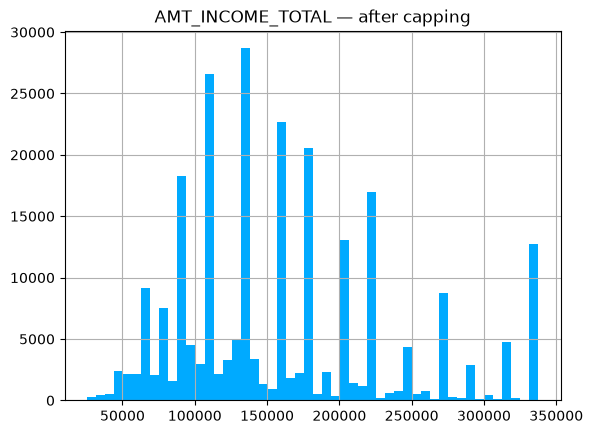

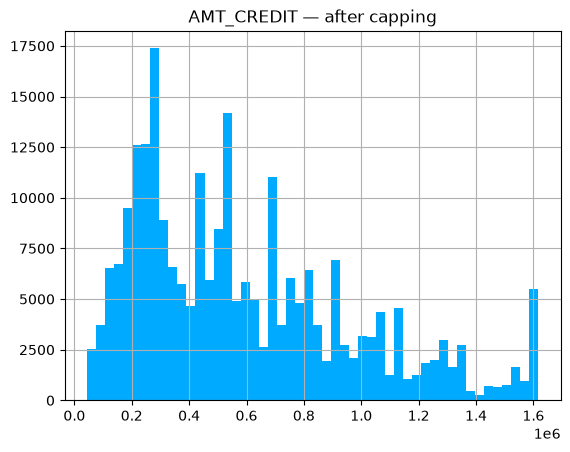

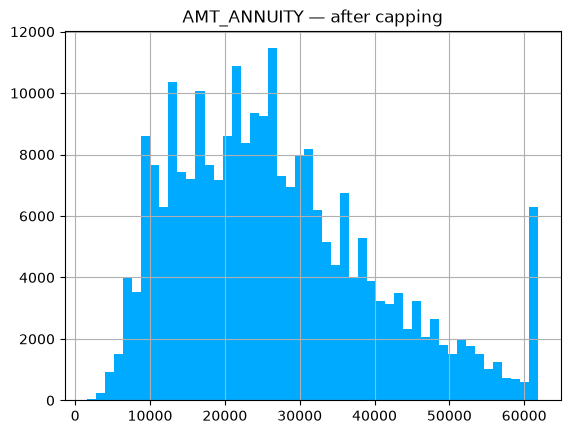

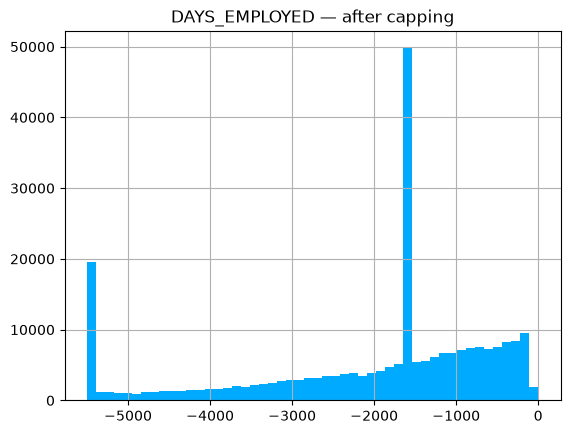

In [20]:
X_train_capped = catalog.load("X_train_capped")
X_test_capped = catalog.load("X_test_capped")

for col in ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "DAYS_EMPLOYED"]:
    X_train_capped[col].hist(bins=50, color = "#00aaff")
    plt.title(f"{col} — after capping")
    plt.show()
